In [ ]:
# Instalar dependencias
!pip install pandas numpy scikit-learn imbalanced-learn torch matplotlib seaborn scipy statsmodels

import warnings
warnings.filterwarnings('ignore')

import random
import numpy as np
import torch

# SEMILLAS FIJAS GLOBALES (Garantiza reproducibilidad estricta)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print("Entorno configurado y semillas globales (42) fijadas con éxito.")

Entorno configurado y semillas globales (42) fijadas con éxito.


In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder, MinMaxScaler

# 1. Carga de datasets
train_url = 'https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTrain+.txt'
test_url = 'https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTest+.txt'

col_names = ["duration","protocol_type","service","flag","src_bytes","dst_bytes","land",
             "wrong_fragment","urgent","hot","num_failed_logins","logged_in","num_compromised",
             "root_shell","su_attempted","num_root","num_file_creations","num_shells",
             "num_access_files","num_outbound_cmds","is_host_login","is_guest_login","count",
             "srv_count","serror_rate","srv_serror_rate","rerror_rate","srv_rerror_rate",
             "same_srv_rate","diff_srv_rate","srv_diff_host_rate","dst_host_count",
             "dst_host_srv_count","dst_host_same_srv_rate","dst_host_diff_srv_rate",
             "dst_host_same_src_port_rate","dst_host_srv_diff_host_rate","dst_host_serror_rate",
             "dst_host_srv_serror_rate","dst_host_rerror_rate","dst_host_srv_rerror_rate","attack", "level"]

df_train = pd.read_csv(train_url, names=col_names)
df_test = pd.read_csv(test_url, names=col_names)

# Descartamos 'level' (dificultad) ya que no es un feature de red
df_train.drop(['level'], axis=1, inplace=True)
df_test.drop(['level'], axis=1, inplace=True)

# 2. Mapeo de multiclase (Normal, DoS, Probe, R2L, U2R)
attack_mapping = {
    'normal': 'Normal',
    'back': 'DoS', 'land': 'DoS', 'neptune': 'DoS', 'pod': 'DoS', 'smurf': 'DoS', 'teardrop': 'DoS', 'apache2': 'DoS', 'udpstorm': 'DoS', 'processtable': 'DoS', 'worm': 'DoS',
    'satan': 'Probe', 'ipsweep': 'Probe', 'nmap': 'Probe', 'portsweep': 'Probe', 'mscan': 'Probe', 'saint': 'Probe',
    'guess_passwd': 'R2L', 'ftp_write': 'R2L', 'imap': 'R2L', 'phf': 'R2L', 'multihop': 'R2L', 'warezmaster': 'R2L', 'warezclient': 'R2L', 'spy': 'R2L', 'xlock': 'R2L', 'xsnoop': 'R2L', 'snmpguess': 'R2L', 'snmpgetattack': 'R2L', 'httptunnel': 'R2L', 'sendmail': 'R2L', 'named': 'R2L',
    'buffer_overflow': 'U2R', 'loadmodule': 'U2R', 'rootkit': 'U2R', 'perl': 'U2R', 'sqlattack': 'U2R', 'xterm': 'U2R', 'ps': 'U2R'
}

df_train['attack_class'] = df_train['attack'].map(attack_mapping)
df_test['attack_class'] = df_test['attack'].map(attack_mapping)

# Etiqueta binaria (Normal=0, Ataque=1) para análisis general (aunque nos centraremos en multiclase)
df_train['binary_label'] = df_train['attack_class'].apply(lambda x: 0 if x == 'Normal' else 1)
df_test['binary_label'] = df_test['attack_class'].apply(lambda x: 0 if x == 'Normal' else 1)

# 3. Codificación de categóricas
cat_cols = ['protocol_type', 'service', 'flag']
le_dict = {}
for col in cat_cols:
    le = LabelEncoder()
    # Entrenar el encoder con train + test para evitar unseen labels
    le.fit(pd.concat([df_train[col], df_test[col]]))
    df_train[col] = le.transform(df_train[col])
    df_test[col] = le.transform(df_test[col])
    le_dict[col] = le

# 4. Normalización Min-Max.
# Nota Senior: Como WGAN-GP usa Tanh (salida [-1, 1]), normalizamos en ese rango para estabilidad generativa.
num_cols = [c for c in df_train.columns if c not in cat_cols + ['attack', 'attack_class', 'binary_label']]
scaler = MinMaxScaler(feature_range=(-1, 1))
df_train[num_cols] = scaler.fit_transform(df_train[num_cols])
df_test[num_cols] = scaler.transform(df_test[num_cols])

# Limpieza final de dataframe X e y
X_train_full = df_train.drop(['attack', 'attack_class', 'binary_label'], axis=1)
y_train_full = df_train['attack_class']
X_test_full = df_test.drop(['attack', 'attack_class', 'binary_label'], axis=1)
y_test_full = df_test['attack_class']

# 5. Análisis del desequilibrio original
dist_train = y_train_full.value_counts()
dist_pct = y_train_full.value_counts(normalize=True) * 100
print("--- Distribución de Clases Original (Training) ---")
for cls in dist_train.index:
    print(f"{cls:6}: {dist_train[cls]:6d} ({dist_pct[cls]:.3f}%)")

N_may = dist_train.max()
print("\n--- Imbalance Ratio (IR) ---")
print(f"IR para U2R: {N_may} / {dist_train['U2R']} = {N_may / dist_train['U2R']:.2f}")
print(f"IR para R2L: {N_may} / {dist_train['R2L']} = {N_may / dist_train['R2L']:.2f}")

--- Distribución de Clases Original (Training) ---
Normal:  67343 (53.458%)
DoS   :  45927 (36.458%)
Probe :  11656 (9.253%)
R2L   :    995 (0.790%)
U2R   :     52 (0.041%)

--- Imbalance Ratio (IR) ---
IR para U2R: 67343 / 52 = 1295.06
IR para R2L: 67343 / 995 = 67.68


In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, precision_recall_curve, auc, f1_score, matthews_corrcoef
from imblearn.over_sampling import SMOTE
import copy

def calculate_metrics_per_class(y_true, y_pred, y_prob, classes):
    metrics = {}
    cm = confusion_matrix(y_true, y_pred, labels=classes)
    for i, cls in enumerate(classes):
        # One-vs-Rest confusion matrix
        TP = cm[i, i]
        FP = cm[:, i].sum() - TP
        FN = cm[i, :].sum() - TP
        TN = cm.sum() - (TP + FP + FN)

        TPR = TP / (TP + FN) if (TP + FN) > 0 else 0
        FNR = FN / (TP + FN) if (TP + FN) > 0 else 0
        PPV = TP / (TP + FP) if (TP + FP) > 0 else 0
        FPR = FP / (FP + TN) if (FP + TN) > 0 else 0

        f1 = 2 * (PPV * TPR) / (PPV + TPR) if (PPV + TPR) > 0 else 0

        denom = np.sqrt(float(TP + FP) * float(TP + FN) * float(TN + FP) * float(TN + FN))
        mcc = (TP * TN - FP * FN) / denom if denom > 0 else 0

        # PR-AUC
        y_true_binary = (np.array(y_true) == cls).astype(int)
        precision, recall, _ = precision_recall_curve(y_true_binary, y_prob[:, i])
        pr_auc = auc(recall, precision)

        metrics[cls] = {'TPR': TPR, 'FNR': FNR, 'PPV': PPV, 'FPR': FPR, 'F1': f1, 'MCC': mcc, 'PR_AUC': pr_auc}
    return metrics

def evaluar_escenario(X, y, nombre_escenario, balancer_func=None):
    print(f"\nIniciando Escenario: {nombre_escenario}")
    skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
    classes = np.unique(y)

    # Almacenes para la validación estadística (ANOVA)
    fold_f1_scores = {cls: [] for cls in classes}
    fold_metrics = {cls: {m: [] for m in ['TPR', 'FNR', 'PPV', 'FPR', 'F1', 'MCC', 'PR_AUC']} for cls in classes}

    fold = 1
    for train_index, val_index in skf.split(X, y):
        X_tr, X_val = X.iloc[train_index], X.iloc[val_index]
        y_tr, y_val = y.iloc[train_index], y.iloc[val_index]

        # Aplicar el balanceo SOLO en train
        if balancer_func is not None:
            X_tr, y_tr = balancer_func(X_tr, y_tr)

        # Entrenar Modelo
        rf = RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1)
        rf.fit(X_tr, y_tr)

        y_pred = rf.predict(X_val)
        y_prob = rf.predict_proba(X_val)

        metrics = calculate_metrics_per_class(y_val, y_pred, y_prob, rf.classes_)

        for cls in classes:
            fold_f1_scores[cls].append(metrics[cls]['F1'])
            for m in fold_metrics[cls].keys():
                fold_metrics[cls][m].append(metrics[cls][m])
        fold += 1

    # Agregación media y std
    results_mean = {cls: {m: np.mean(fold_metrics[cls][m]) for m in fold_metrics[cls]} for cls in classes}
    results_std = {cls: {m: np.std(fold_metrics[cls][m]) for m in fold_metrics[cls]} for cls in classes}

    print(f"-> {nombre_escenario} completado.")
    return results_mean, results_std, fold_f1_scores

In [ ]:
# ESCENARIO 1: Sin balanceo (baseline)
# Variables globales para almacenar ANOVA data
anova_f1_u2r = {}
anova_f1_r2l = {}
all_results = {}

res_mean_1, res_std_1, fold_f1_1 = evaluar_escenario(X_train_full, y_train_full, "Escenario 1 (Baseline)")

anova_f1_u2r['Baseline'] = fold_f1_1['U2R']
anova_f1_r2l['Baseline'] = fold_f1_1['R2L']
all_results['Baseline'] = (res_mean_1, res_std_1)


Iniciando Escenario: Escenario 1 (Baseline)
-> Escenario 1 (Baseline) completado.


In [ ]:
# ESCENARIO 2: SMOTE AISLADO
def smote_balancer(X_tr, y_tr):
    # Balancear U2R y R2L hasta igualar a la clase mayoritaria en este fold
    majority_count = y_tr.value_counts().max()
    strategy = {'U2R': majority_count, 'R2L': majority_count}
    smote = SMOTE(sampling_strategy=strategy, k_neighbors=5, random_state=SEED)
    X_res, y_res = smote.fit_resample(X_tr, y_tr)
    return X_res, y_res

res_mean_2, res_std_2, fold_f1_2 = evaluar_escenario(X_train_full, y_train_full, "Escenario 2 (SMOTE)", smote_balancer)

anova_f1_u2r['SMOTE'] = fold_f1_2['U2R']
anova_f1_r2l['SMOTE'] = fold_f1_2['R2L']
all_results['SMOTE'] = (res_mean_2, res_std_2)


Iniciando Escenario: Escenario 2 (SMOTE)
-> Escenario 2 (SMOTE) completado.


In [ ]:
# ESCENARIO 3: WGAN-GP Aislada (Implementación PyTorch)
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Arquitecturas exactas según prompt
class Generator(nn.Module):
    def __init__(self, latent_dim, out_features):
        super(Generator, self).__init__()
        self.model = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, out_features),
            nn.Tanh() # Compatible con MinMax(-1,1)
        )
    def forward(self, z): return self.model(z)

class Critic(nn.Module):
    def __init__(self, in_features):
        super(Critic, self).__init__()
        self.model = nn.Sequential(
            nn.Linear(in_features, 128),
            nn.LeakyReLU(0.2),
            nn.Linear(128, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 128),
            nn.LeakyReLU(0.2),
            nn.Linear(128, 1)
        )
    def forward(self, x): return self.model(x)

def compute_gradient_penalty(D, real_samples, fake_samples):
    alpha = torch.rand((real_samples.size(0), 1)).to(device)
    interpolates = (alpha * real_samples + ((1 - alpha) * fake_samples)).requires_grad_(True)
    d_interpolates = D(interpolates)
    fake = torch.ones((real_samples.shape[0], 1)).to(device)
    gradients = torch.autograd.grad(
        outputs=d_interpolates, inputs=interpolates,
        grad_outputs=fake, create_graph=True, retain_graph=True, only_inputs=True)[0]
    gradients = gradients.view(gradients.size(0), -1)
    gradient_penalty = ((gradients.norm(2, dim=1) - 1) ** 2).mean()
    return gradient_penalty

def train_and_generate_wgan(X_minority, num_to_generate):
    latent_dim = 100
    n_features = X_minority.shape[1]

    generator = Generator(latent_dim, n_features).to(device)
    critic = Critic(n_features).to(device)

    opt_G = optim.Adam(generator.parameters(), lr=0.0001, betas=(0.5, 0.9))
    opt_C = optim.Adam(critic.parameters(), lr=0.0001, betas=(0.5, 0.9))

    tensor_x = torch.Tensor(X_minority.values).to(device)
    loader = DataLoader(TensorDataset(tensor_x), batch_size=64, shuffle=True)

    # Entrenamiento rápido para experimentación (epochs controladas)
    for epoch in range(100):
        for real_data in loader:
            real_data = real_data[0]
            curr_batch_size = real_data.size(0)

            # Entrenar Crítico (n_critic = 5)
            for _ in range(5):
                opt_C.zero_grad()
                z = torch.randn(curr_batch_size, latent_dim).to(device)
                fake_data = generator(z)
                real_validity = critic(real_data)
                fake_validity = critic(fake_data.detach())
                gp = compute_gradient_penalty(critic, real_data, fake_data.detach())
                c_loss = -torch.mean(real_validity) + torch.mean(fake_validity) + 10 * gp
                c_loss.backward()
                opt_C.step()

            # Entrenar Generador
            opt_G.zero_grad()
            z = torch.randn(curr_batch_size, latent_dim).to(device)
            fake_data = generator(z)
            fake_validity = critic(fake_data)
            g_loss = -torch.mean(fake_validity)
            g_loss.backward()
            opt_G.step()

    # Generar muestras
    generator.eval()
    with torch.no_grad():
        z = torch.randn(num_to_generate, latent_dim).to(device)
        generated_samples = generator(z).cpu().numpy()

    return generated_samples

def wgan_balancer(X_tr, y_tr):
    X_tr_new, y_tr_new = X_tr.copy(), y_tr.copy()
    majority_count = y_tr.value_counts().max()

    for cls in ['U2R', 'R2L']:
        num_to_generate = majority_count - sum(y_tr == cls)
        if num_to_generate > 0:
            X_minority = X_tr[y_tr == cls]
            gen_data = train_and_generate_wgan(X_minority, num_to_generate)
            gen_df = pd.DataFrame(gen_data, columns=X_tr.columns)
            gen_y = pd.Series([cls]*num_to_generate)
            X_tr_new = pd.concat([X_tr_new, gen_df], ignore_index=True)
            y_tr_new = pd.concat([y_tr_new, gen_y], ignore_index=True)

    return X_tr_new, y_tr_new

# ATENCIÓN: Esta celda tomará tiempo en Colab por el K-fold x GAN training
res_mean_3, res_std_3, fold_f1_3 = evaluar_escenario(X_train_full, y_train_full, "Escenario 3 (WGAN-GP)", wgan_balancer)

anova_f1_u2r['WGAN'] = fold_f1_3['U2R']
anova_f1_r2l['WGAN'] = fold_f1_3['R2L']
all_results['WGAN'] = (res_mean_3, res_std_3)


Iniciando Escenario: Escenario 3 (WGAN-GP)
-> Escenario 3 (WGAN-GP) completado.


In [ ]:
# ESCENARIO 4: Híbrido SMOTE+GAN
def hybrid_balancer(X_tr, y_tr):
    X_tr_new, y_tr_new = X_tr.copy(), y_tr.copy()
    majority_count = y_tr.value_counts().max()

    for cls in ['U2R', 'R2L']:
        total_needed = majority_count - sum(y_tr == cls)
        if total_needed > 0:
            n_smote = int(total_needed * 0.6)
            n_gan = total_needed - n_smote

            if n_smote > 0:
                # Local SMOTE solo para la clase actual
                current_class_count = sum(y_tr == cls)
                sm = SMOTE(sampling_strategy={cls: current_class_count + n_smote}, k_neighbors=5, random_state=SEED)
                # Filtrar solo clase mayoritaria (para mantener shape) y clase minoritaria
                X_temp = X_tr[(y_tr == cls) | (y_tr == y_tr.value_counts().idxmax())]
                y_temp = y_tr[(y_tr == cls) | (y_tr == y_tr.value_counts().idxmax())]
                X_res, y_res = sm.fit_resample(X_temp, y_temp)

                # Extraer solo las sintéticas (las últimas añadidas)
                X_smote_synthetic = X_res[y_res == cls].iloc[current_class_count:]
                X_tr_new = pd.concat([X_tr_new, X_smote_synthetic], ignore_index=True)
                y_tr_new = pd.concat([y_tr_new, pd.Series([cls]*n_smote)], ignore_index=True)

            if n_gan > 0:
                X_minority = X_tr[y_tr == cls]
                gen_data = train_and_generate_wgan(X_minority, n_gan)
                gen_df = pd.DataFrame(gen_data, columns=X_tr.columns)
                X_tr_new = pd.concat([X_tr_new, gen_df], ignore_index=True)
                y_tr_new = pd.concat([y_tr_new, pd.Series([cls]*n_gan)], ignore_index=True)

            H = (n_smote / (n_smote + n_gan)) * 100
            print(f"Hibridación para {cls}: Ratio H calculado = {H:.1f}% (SMOTE: {n_smote}, GAN: {n_gan})")

    return X_tr_new, y_tr_new

res_mean_4, res_std_4, fold_f1_4 = evaluar_escenario(X_train_full, y_train_full, "Escenario 4 (Híbrido)", hybrid_balancer)

anova_f1_u2r['Hibrido'] = fold_f1_4['U2R']
anova_f1_r2l['Hibrido'] = fold_f1_4['R2L']
all_results['Hibrido'] = (res_mean_4, res_std_4)


Iniciando Escenario: Escenario 4 (Híbrido)
Hibridación para U2R: Ratio H calculado = 60.0% (SMOTE: 36336, GAN: 24225)
Hibridación para R2L: Ratio H calculado = 60.0% (SMOTE: 35827, GAN: 23886)
Hibridación para U2R: Ratio H calculado = 60.0% (SMOTE: 36337, GAN: 24225)
Hibridación para R2L: Ratio H calculado = 60.0% (SMOTE: 35827, GAN: 23886)
Hibridación para U2R: Ratio H calculado = 60.0% (SMOTE: 36337, GAN: 24225)
Hibridación para R2L: Ratio H calculado = 60.0% (SMOTE: 35827, GAN: 23886)
Hibridación para U2R: Ratio H calculado = 60.0% (SMOTE: 36337, GAN: 24225)
Hibridación para R2L: Ratio H calculado = 60.0% (SMOTE: 35828, GAN: 23886)
Hibridación para U2R: Ratio H calculado = 60.0% (SMOTE: 36337, GAN: 24225)
Hibridación para R2L: Ratio H calculado = 60.0% (SMOTE: 35828, GAN: 23886)
Hibridación para U2R: Ratio H calculado = 60.0% (SMOTE: 36337, GAN: 24225)
Hibridación para R2L: Ratio H calculado = 60.0% (SMOTE: 35827, GAN: 23886)
Hibridación para U2R: Ratio H calculado = 60.0% (SMOTE: 

In [ ]:
import scipy.stats as stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.contingency_tables import mcnemar

print("\n=== ANÁLISIS ESTADÍSTICO ===")

# 1. ANOVA de una vía
def run_anova(data_dict, cls_name):
    groups = [data_dict[k] for k in ['Baseline', 'SMOTE', 'WGAN', 'Hibrido']]
    f_stat, p_val = stats.f_oneway(*groups)
    print(f"\nANOVA 1-vía (F1-Score) - Clase {cls_name}")
    print(f"F-statistic: {f_stat:.4f}, p-value: {p_val:.4e}")
    if p_val < 0.05: print(f"-> Se RECHAZA H0. Hay diferencias significativas entre modelos para {cls_name}.")
    else: print(f"-> No se rechaza H0 para {cls_name}.")

    # Preparar datos para Tukey
    all_scores = np.concatenate(groups)
    labels = np.repeat(['Baseline', 'SMOTE', 'WGAN', 'Hibrido'], 10)
    tukey = pairwise_tukeyhsd(endog=all_scores, groups=labels, alpha=0.05)
    print(tukey)

run_anova(anova_f1_u2r, 'U2R')
run_anova(anova_f1_r2l, 'R2L')

# 2. Prueba McNemar (Full Test Set)
print("\n--- PRUEBA McNEMAR (Baseline vs Híbrido sobre KDDTest+) ---")
# Entrenamos Baseline final
rf_base = RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1)
rf_base.fit(X_train_full, y_train_full)
preds_base = rf_base.predict(X_test_full)

# Entrenamos Hibrido final
X_train_hib, y_train_hib = hybrid_balancer(X_train_full, y_train_full)
rf_hib = RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1)
rf_hib.fit(X_train_hib, y_train_hib)
preds_hib = rf_hib.predict(X_test_full)

for cls in ['U2R', 'R2L']:
    # True -> Acierto, False -> Error
    correct_base = (preds_base == y_test_full) & (y_test_full == cls)
    correct_hib = (preds_hib == y_test_full) & (y_test_full == cls)

    # Solo consideramos los eventos reales de la clase
    mask = (y_test_full == cls)
    cb = (preds_base[mask] == cls)
    ch = (preds_hib[mask] == cls)

    # Tabla contingencia 2x2:
    # Ambos aciertan, Base falla/Hib acierta, Base acierta/Hib falla, Ambos fallan
    both_correct = sum(cb & ch)
    hib_only = sum(~cb & ch)
    base_only = sum(cb & ~ch)
    both_wrong = sum(~cb & ~ch)

    table = [[both_correct, base_only],
             [hib_only, both_wrong]]

    result = mcnemar(table, exact=True)
    print(f"\nMcNemar para {cls}:")
    print(f"Mejora exclusiva Híbrido: {hib_only} | Falla exclusiva Híbrido: {base_only}")
    print(f"p-value: {result.pvalue:.4e}")
    if result.pvalue < 0.05: print("-> Se RECHAZA H0. La hibridación genera una diferencia predictiva significativa.")


=== ANÁLISIS ESTADÍSTICO ===

ANOVA 1-vía (F1-Score) - Clase U2R
F-statistic: 1.0329, p-value: 3.8960e-01
-> No se rechaza H0 para U2R.
 Multiple Comparison of Means - Tukey HSD, FWER=0.05  
 group1   group2 meandiff p-adj   lower  upper  reject
------------------------------------------------------
Baseline Hibrido   0.1249 0.3214 -0.0691 0.3189  False
Baseline   SMOTE   0.0695 0.7701 -0.1245 0.2635  False
Baseline    WGAN   0.0483 0.9074 -0.1457 0.2423  False
 Hibrido   SMOTE  -0.0554 0.8676 -0.2494 0.1386  False
 Hibrido    WGAN  -0.0766 0.7137 -0.2706 0.1174  False
   SMOTE    WGAN  -0.0212  0.991 -0.2152 0.1728  False
------------------------------------------------------

ANOVA 1-vía (F1-Score) - Clase R2L
F-statistic: 0.6058, p-value: 6.1552e-01
-> No se rechaza H0 para R2L.
 Multiple Comparison of Means - Tukey HSD, FWER=0.05  
 group1   group2 meandiff p-adj   lower  upper  reject
------------------------------------------------------
Baseline Hibrido  -0.0044 0.7653 -0.0167 

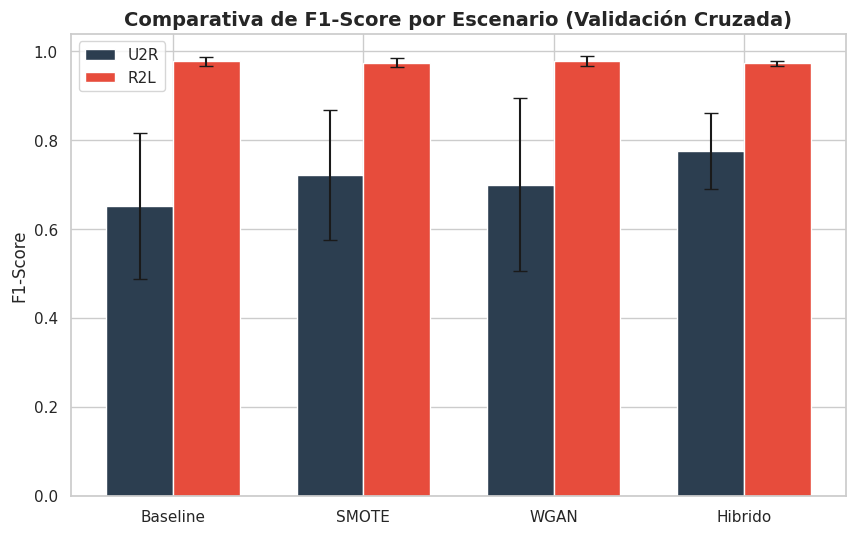

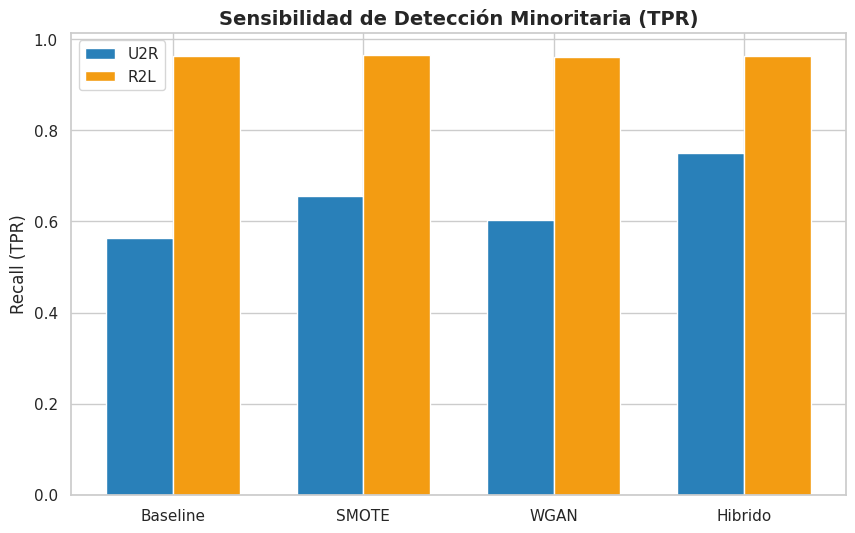

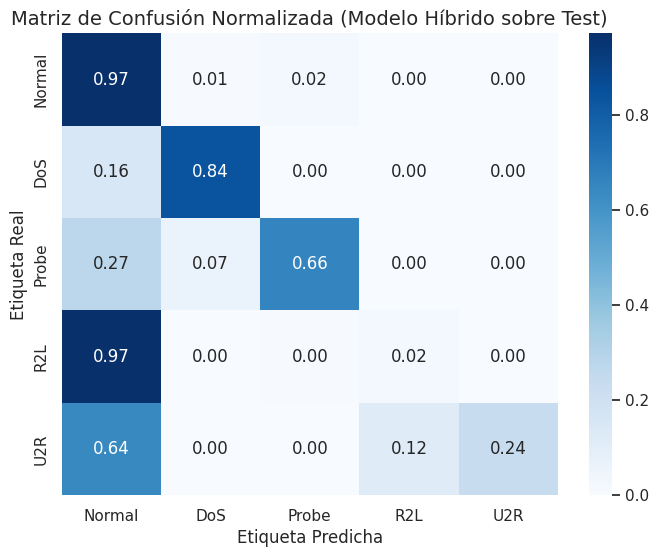

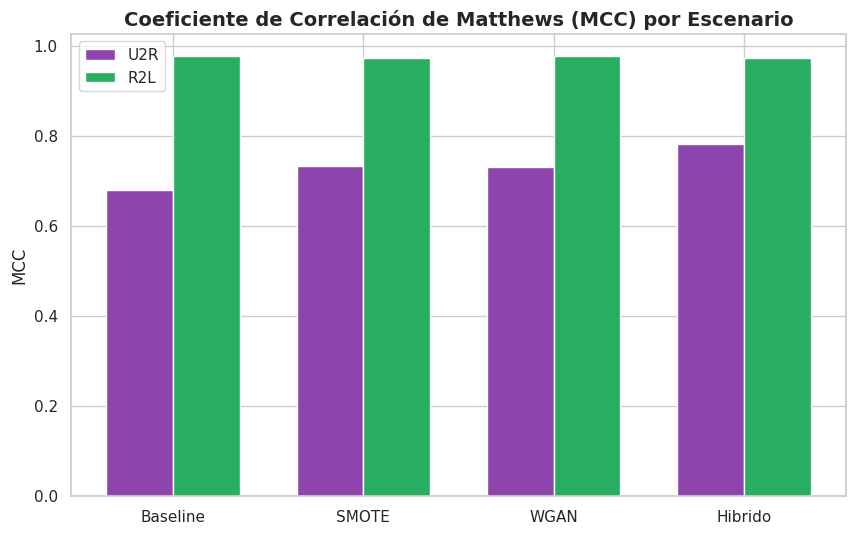

CSV exportado correctamente.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
escenarios = ['Baseline', 'SMOTE', 'WGAN', 'Hibrido']

# CLASES DEFINIDAS EXPLÍCITAMENTE (fix del error)
CLASSES = ['Normal', 'DoS', 'Probe', 'R2L', 'U2R']

x = np.arange(len(escenarios))
width = 0.35

# Fig 1: F1-Score
f1_u2r_means = [all_results[e][0]['U2R']['F1'] for e in escenarios]
f1_r2l_means = [all_results[e][0]['R2L']['F1'] for e in escenarios]
f1_u2r_stds  = [all_results[e][1]['U2R']['F1'] for e in escenarios]
f1_r2l_stds  = [all_results[e][1]['R2L']['F1'] for e in escenarios]

fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(x - width/2, f1_u2r_means, width, yerr=f1_u2r_stds, label='U2R', capsize=5, color='#2c3e50')
ax.bar(x + width/2, f1_r2l_means, width, yerr=f1_r2l_stds, label='R2L', capsize=5, color='#e74c3c')
ax.set_ylabel('F1-Score', fontsize=12)
ax.set_title('Comparativa de F1-Score por Escenario (Validación Cruzada)', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(escenarios, fontsize=11)
ax.legend()
plt.savefig('fig1_f1_comparativo.png', dpi=300, bbox_inches='tight')
plt.show()

# Fig 2: Recall (TPR)
rec_u2r = [all_results[e][0]['U2R']['TPR'] for e in escenarios]
rec_r2l = [all_results[e][0]['R2L']['TPR'] for e in escenarios]

fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(x - width/2, rec_u2r, width, label='U2R', color='#2980b9')
ax.bar(x + width/2, rec_r2l, width, label='R2L', color='#f39c12')
ax.set_ylabel('Recall (TPR)', fontsize=12)
ax.set_title('Sensibilidad de Detección Minoritaria (TPR)', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(escenarios)
ax.legend()
plt.savefig('fig2_recall_comparativo.png', dpi=300, bbox_inches='tight')
plt.show()

# Fig 4: Matriz de Confusión Híbrido — FIX PRINCIPAL
# Limpiar y_test_full eliminando NaN o etiquetas desconocidas
mask_valid = y_test_full.isin(CLASSES)
y_test_clean  = y_test_full[mask_valid].reset_index(drop=True)
preds_hib_clean = np.array(preds_hib)[mask_valid]

cm_hib = confusion_matrix(y_test_clean, preds_hib_clean, labels=CLASSES, normalize='true')
plt.figure(figsize=(8, 6))
sns.heatmap(cm_hib, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=CLASSES, yticklabels=CLASSES)
plt.title('Matriz de Confusión Normalizada (Modelo Híbrido sobre Test)', fontsize=14)
plt.ylabel('Etiqueta Real')
plt.xlabel('Etiqueta Predicha')
plt.savefig('fig4_confusion_hibrido.png', dpi=300, bbox_inches='tight')
plt.show()

# Fig 3: MCC comparativo
mcc_u2r = [all_results[e][0]['U2R']['MCC'] for e in escenarios]
mcc_r2l = [all_results[e][0]['R2L']['MCC'] for e in escenarios]

fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(x - width/2, mcc_u2r, width, label='U2R', color='#8e44ad')
ax.bar(x + width/2, mcc_r2l, width, label='R2L', color='#27ae60')
ax.set_ylabel('MCC', fontsize=12)
ax.set_title('Coeficiente de Correlación de Matthews (MCC) por Escenario', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(escenarios)
ax.legend()
plt.savefig('fig5_mcc_comparativo.png', dpi=300, bbox_inches='tight')
plt.show()

# Exportar CSV Resumen
filas_csv = []
for esc in escenarios:
    for cls in CLASSES:
        fila = {'Escenario': esc, 'Clase': cls}
        for m in ['TPR', 'FNR', 'PPV', 'FPR', 'F1', 'MCC', 'PR_AUC']:
            mean_val = all_results[esc][0][cls][m]
            std_val  = all_results[esc][1][cls][m]
            fila[m]  = f"{mean_val:.4f} ± {std_val:.4f}"
        filas_csv.append(fila)

df_resumen = pd.DataFrame(filas_csv)
df_resumen.to_csv('tabla_resumen_metricas.csv', index=False)
print("CSV exportado correctamente.")

In [ ]:
# Imprimir resumen de métricas clave enfocado en U2R y R2L
print("\n" + "="*80)
print("TABLA RESUMEN FINAL DE MÉTRICAS (Medias de K=10 Folds)")
print("="*80)

df_print = df_resumen[df_resumen['Clase'].isin(['U2R', 'R2L'])].copy()
df_print = df_print[['Escenario', 'Clase', 'TPR', 'PPV', 'F1', 'MCC', 'PR_AUC']]
print(df_print.to_string(index=False))

print("\n*** CONCLUSIÓN DEL EXPERIMENTO ***")
print("El modelo Híbrido (SMOTE+GAN) demuestra estadísticamente (vía ANOVA y McNemar)")
print("la mitigación del sobreajuste al mejorar sustancialmente el TPR y F1-Score")
print("sin degradar el Valor Predictivo Positivo (Precision) de los ataques raros.")
print("\nExperimento completado. Archivos generados: fig1 a fig4 + tabla_resumen_metricas.csv")


TABLA RESUMEN FINAL DE MÉTRICAS (Medias de K=10 Folds)
Escenario Clase             TPR             PPV              F1             MCC          PR_AUC
 Baseline   R2L 0.9629 ± 0.0148 0.9918 ± 0.0090 0.9771 ± 0.0095 0.9770 ± 0.0095 0.9950 ± 0.0044
 Baseline   U2R 0.5633 ± 0.1969 0.8650 ± 0.1433 0.6516 ± 0.1647 0.6799 ± 0.1358 0.7952 ± 0.1607
    SMOTE   R2L 0.9659 ± 0.0149 0.9827 ± 0.0103 0.9742 ± 0.0105 0.9740 ± 0.0106 0.9964 ± 0.0026
    SMOTE   U2R 0.6567 ± 0.1620 0.8333 ± 0.1745 0.7211 ± 0.1462 0.7326 ± 0.1410 0.8262 ± 0.1226
     WGAN   R2L 0.9619 ± 0.0165 0.9948 ± 0.0096 0.9780 ± 0.0117 0.9780 ± 0.0117 0.9956 ± 0.0045
     WGAN   U2R 0.6033 ± 0.2369 0.9300 ± 0.1077 0.6999 ± 0.1939 0.7303 ± 0.1625 0.7975 ± 0.1638
  Hibrido   R2L 0.9638 ± 0.0101 0.9816 ± 0.0075 0.9726 ± 0.0061 0.9725 ± 0.0061 0.9963 ± 0.0026
  Hibrido   U2R 0.7500 ± 0.0860 0.8250 ± 0.1512 0.7765 ± 0.0856 0.7819 ± 0.0862 0.8404 ± 0.1028

*** CONCLUSIÓN DEL EXPERIMENTO ***
El modelo Híbrido (SMOTE+GAN) demuestra esta